# Local search

**Group E01** — Project 01, Artificial Intelligence 2026-27. Supporting notebook of the main one.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # so Python finds the 'src' folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.model import Problem, State, Stop
from src import informed, local_search, csp

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

prob = Problem.from_csv("../data_tiny")          # development dataset
prob_small = Problem.from_csv("../data_small")   # larger dataset, used to check that the code scales

In [2]:
# Greedy and A* (h1, h2) on both datasets. Needed by the local search and the comparison.
df_inf, states_inf, plans_inf = informed.run_all(prob)
df_inf_small, states_inf_small, plans_inf_small = informed.run_all(prob_small)

## 4.2 Local search: Hill-Climbing

**Initial solution:** the plan found by Greedy (h1). A solution is a plan: the visiting order of every collection and delivery list of every vehicle and day. The **neighbourhood** has four moves, as required by the brief:

* *relocate*: move a stop to another position of the same vehicle,
* *swap*: exchange two stops of the same vehicle,
* *2-opt*: reverse a segment of consecutive stops,
* *move*: move a stop to another vehicle.

Each iteration evaluates **all** the neighbours, discards the infeasible ones (flow, capacity, windows, dwell) and moves to the best one (steepest descent of the cost, i.e. steepest-ascent hill-climbing on `-cost`). It stops at a **local optimum** (no neighbour is better). A **plateau** is a set of neighbours with the same cost; with `max_sideways > 0` the search may cross it with equal-cost moves, never returning to a plan already visited. The moves 2-opt, swap and relocate are our implementation choices; the lecture slides show hill-climbing on the 8-queens problem only.

In [3]:
start_plan = plans_inf[("greedy", "h1")]
start_cost = prob.calculate_cost(prob.plan_to_state(start_plan))

best_plan, hist = local_search.hill_climbing(prob, start_plan, max_sideways=0)
best_plan_sw, hist_sw = local_search.hill_climbing(prob, start_plan, max_sideways=10)
hc_tiny = pd.DataFrame(hist)
hc_tiny_sw = pd.DataFrame(hist_sw)

print("Start (Greedy h1): %.2f km" % start_cost)
print("Hill-Climbing    : %.2f km in %d iterations (%.2f s)" % (hc_tiny.cost_km.iloc[-1], len(hc_tiny) - 1, hist[0]["seconds"]))
print("With sideways    : %.2f km in %d iterations (%.2f s)" % (hc_tiny_sw.cost_km.iloc[-1], len(hc_tiny_sw) - 1, hist_sw[0]["seconds"]))
print("Final plan feasible:", prob.is_feasible_full(prob.plan_to_state(best_plan)))
hc_tiny[["iteration", "move", "cost_km", "neighbours"]]

Start (Greedy h1): 724.28 km
Hill-Climbing    : 580.90 km in 5 iterations (0.43 s)
With sideways    : 580.90 km in 10 iterations (0.82 s)
Final plan feasible: True


,iteration,move,cost_km,neighbours
0,0,start,724.28,0
1,1,move,683.61,125
2,2,move,649.19,127
3,3,move,627.96,129
4,4,move,616.56,134
5,5,move,580.90,132


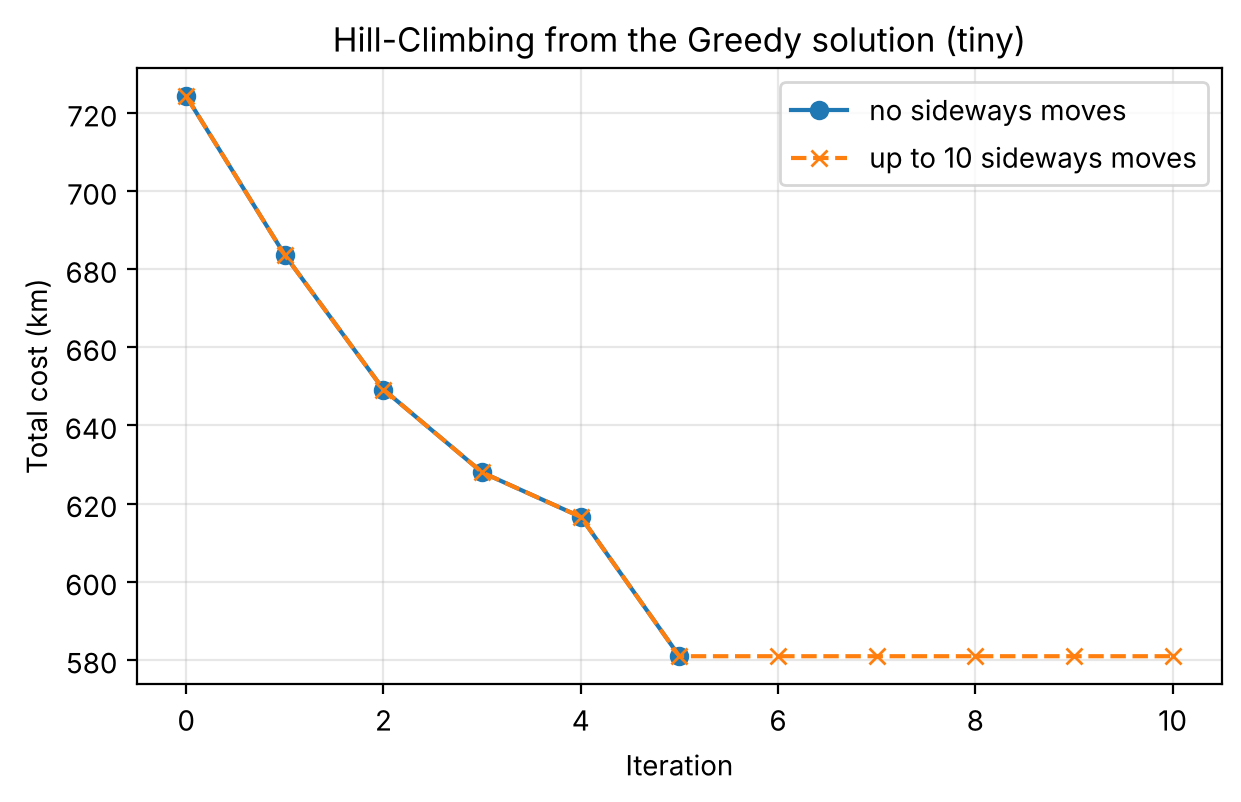

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(hc_tiny.iteration, hc_tiny.cost_km, marker="o", label="no sideways moves")
plt.plot(hc_tiny_sw.iteration, hc_tiny_sw.cost_km, marker="x", linestyle="--", label="up to 10 sideways moves")
plt.xlabel("Iteration")
plt.ylabel("Total cost (km)")
plt.title("Hill-Climbing from the Greedy solution (tiny)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Start (Greedy h1): 1090.63 km
Hill-Climbing    : 785.50 km in 11 iterations (9.1 s)
Final plan feasible: True


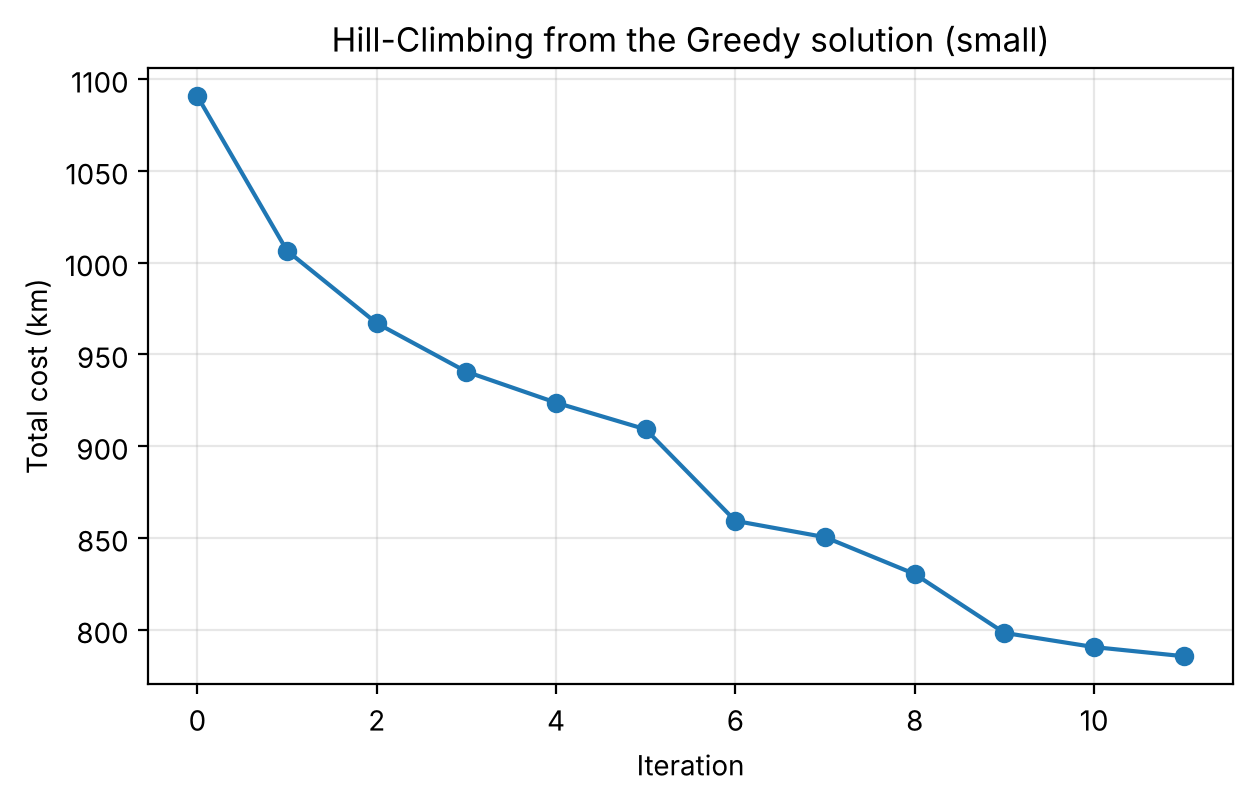

,iteration,move,cost_km,neighbours
0,0,start,1090.63,0
1,1,move,1006.44,622
2,2,move,966.95,623
3,3,move,940.53,643
4,4,move,923.65,667
5,5,relocate,909.12,673
6,6,move,859.24,671
7,7,2-opt,850.37,682
8,8,move,830.29,682
9,9,move,798.22,710


In [5]:
# Same experiment on the small dataset (starts from its own Greedy solution)
start_small = plans_inf_small[("greedy", "h1")]
best_small, hist_small = local_search.hill_climbing(prob_small, start_small)
hc_small = pd.DataFrame(hist_small)

print("Start (Greedy h1): %.2f km" % hc_small.cost_km.iloc[0])
print("Hill-Climbing    : %.2f km in %d iterations (%.1f s)" % (hc_small.cost_km.iloc[-1], len(hc_small) - 1, hist_small[0]["seconds"]))
print("Final plan feasible:", prob_small.is_feasible_full(prob_small.plan_to_state(best_small)))

plt.figure(figsize=(7, 4))
plt.plot(hc_small.iteration, hc_small.cost_km, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Total cost (km)")
plt.title("Hill-Climbing from the Greedy solution (small)")
plt.grid(alpha=0.3)
plt.show()
hc_small[["iteration", "move", "cost_km", "neighbours"]]

In [6]:
# Which moves produced the improvements?
pd.concat([hc_tiny.assign(dataset="tiny"), hc_small.assign(dataset="small")]).query("iteration > 0").groupby(["dataset", "move"]).size()

dataset  move    
small    2-opt       1
         move        9
         relocate    1
tiny     move        5
dtype: int64

### Observations (executed results)

* **Tiny:** 724.28 km -> 580.90 km (-19.8 %) in 5 iterations (about 0.5 s). **Small:** 1090.63 km -> 785.50 km (-28.0 %) in 11 iterations (about 9 s).
* Almost every accepted move is *move* (a stop goes to another vehicle): 5 of 5 on tiny and 9 of 11 on small (plus 1 relocate and 1 2-opt). The improvement comes from the **vehicle assignment** inherited from the first split; the order inside each list was already good (A* is optimal per list).
* Every plan visited is feasible, because infeasible neighbours are discarded, and the final plans pass the independent checker (`is_feasible_full`).
* The search stops at a **local optimum**: none of the ~130 (tiny) or ~700 (small) neighbours is better. This does not prove that 580.90 km or 785.50 km are the global optimum.
* **Plateaus.** Allowing up to 10 sideways moves on tiny adds 5 iterations of equal cost and ends at the same 580.90 km, so in this case the plateau did not hide a better solution.
* **Cost of the method.** Every iteration simulates all neighbours; it grows from about 0.5 s (tiny) to about 9 s (small), so it would be slow for much larger datasets.